# Introduction

You are welcome to fork this notebook, improve it, and try to get a better score on the competition leaderboard.

Import the packages that will be used:

In [33]:
import os
import kagglehub

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

Download the competition dataset:

In [34]:
path = kagglehub.competition_download('flower-species-2026')

path

'C:\\Users\\ricky\\.cache\\kagglehub\\competitions\\flower-species-2026'

# Training data

Read the training data from a CSV file, using the *id* column as index:

In [35]:
df = pd.read_csv(os.path.join(path, 'train.csv'), index_col='id')

df

,sepal_length,sepal_width,petal_length,petal_width,species
id,,,,,
1,6.4,3.2,4.6,1.5,versicolor
2,5.6,3.6,1.4,0.3,setosa
3,7.0,2.6,4.9,1.5,versicolor
4,6.0,4.4,2.0,0.5,setosa
5,6.0,4.2,1.8,0.3,setosa
...,...,...,...,...,...
116,5.4,3.4,1.6,0.2,setosa
117,6.5,3.1,5.7,2.2,virginica
118,7.7,3.6,6.4,2.6,virginica


Analyze some summary statistics for each feature column:

In [ ]:
feature_columns = df.columns[:4].drop('sepal_width')

df[feature_columns].describe()

,sepal_length,sepal_width,petal_length,petal_width
count,120.000000,120.000000,120.00000,120.000000
mean,6.505000,3.459167,4.22750,1.401667
std,0.870801,0.480982,1.91535,0.842663
min,4.800000,2.300000,1.30000,0.200000
25%,5.700000,3.200000,1.90000,0.400000
50%,6.400000,3.400000,4.70000,1.500000
75%,7.100000,3.800000,5.70000,2.100000
max,8.800000,4.900000,7.70000,2.800000


Above, the 25% / 50% / 75% percentiles are also known as first / second / third quartiles (Q1 / Q2 / Q3).
* Q1 is the value below which 25% of the data fall.
* Q2 is the value below which 50% of the data fall (it is the median).
* Q3 is the value below which 75% of the data fall.

Use a box plot to visualize the spread of values for each feature:

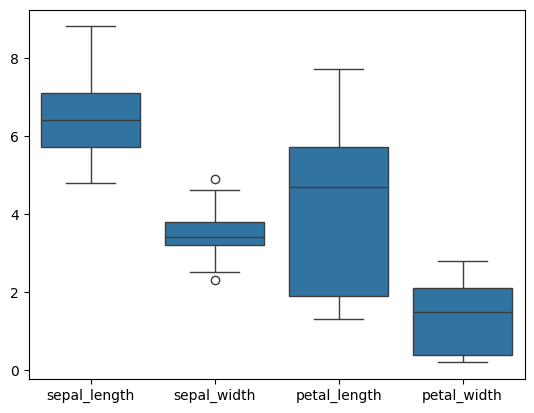

In [37]:
sns.boxplot(data=df, color='tab:blue');

For each feature in the box plot above:
* The horizontal line inside the box represents the median (Q2).
* The box encloses the middle 50% of the data, from Q1 to Q3.
* The difference (Q3 - Q1) is called the *interquartile range* or IQR.
* The upper whisker extends to the greatest data point, up to a maximum of (Q3 + 1.5 * IQR).
* The lower whisker extends to the smallest data point, down to a minimum of (Q1 - 1.5 * IQR).
* Any points beyond the whiskers are treated as outliers and are shown as individual markers.

Analyze the class balance:

In [38]:
target_column = df.columns[-1]

df[target_column].value_counts().sort_index().to_frame()

,count
species,
setosa,40
versicolor,40
virginica,40


The training set is perfectly balanced (it has the same number of training samples for each class).

Analyze some summary statistics for each class:

In [39]:
df.groupby(target_column).agg(['mean', 'std'])

sepal_length           sepal_width           petal_length  \
                   mean       std        mean       std         mean   
species                                                                
setosa           5.6425  0.380881      3.8775  0.428765       1.7500   
versicolor       6.5600  0.518281      3.1500  0.333590       4.7200   
virginica        7.3125  0.682074      3.3500  0.347887       6.2125   

                     petal_width            
                 std        mean       std  
species                                     
setosa      0.211224      0.3525  0.124009  
versicolor  0.481557      1.5300  0.225548  
virginica   0.576100      2.3225  0.291317

The results above suggest that, on average, *setosa* has:
* shorter *sepal_length*, *petal_length*, and *petal_width* than other species;
* longer *sepal_width* than other species.

Draw a box plot for each feature, and compare its value distribution across classes:

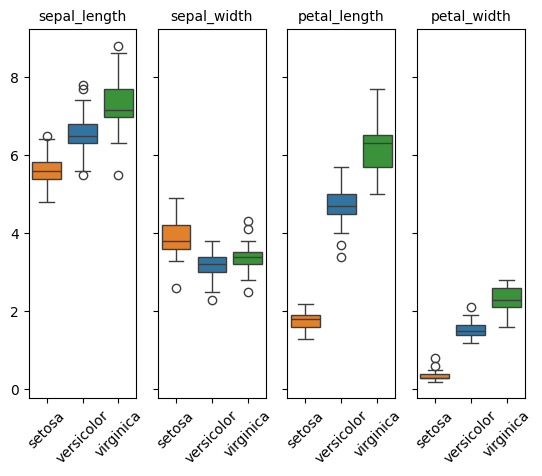

In [40]:
order = sorted(df[target_column].unique())

fig, ax = plt.subplots(1, len(feature_columns), sharey=True)

for i, col in enumerate(feature_columns):
    sns.boxplot(data=df,
                x=target_column,
                y=col,
                hue=target_column,
                order=order,
                ax=ax[i])

    ax[i].set_title(feature_columns[i], fontsize='medium')
    ax[i].set_xlabel('')
    ax[i].set_ylabel('')
    ax[i].tick_params(axis='x', rotation=45)

# Feature correlations

Compute the correlations between features:

In [41]:
corr = df[feature_columns].corr()

corr

,sepal_length,sepal_width,petal_length,petal_width
sepal_length,1.000000,-0.124704,0.861168,0.802657
sepal_width,-0.124704,1.000000,-0.446646,-0.382983
petal_length,0.861168,-0.446646,1.000000,0.960686
petal_width,0.802657,-0.382983,0.960686,1.000000


Plot a heatmap to visualize the feature correlations:

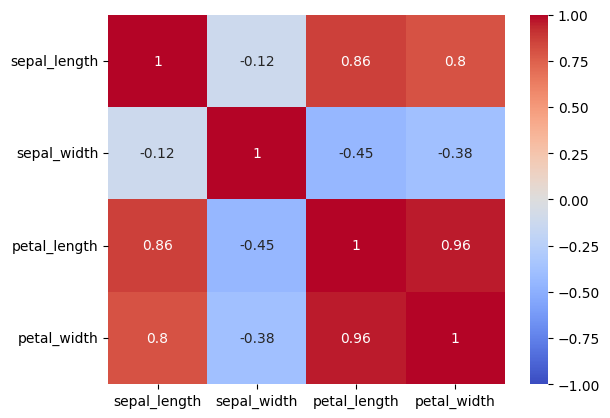

In [42]:
ax = sns.heatmap(data=corr, vmin=-1, vmax=1, annot=True, cmap='coolwarm')

ax.tick_params(axis='y', rotation=0)

These two features seem to be highly correlated:

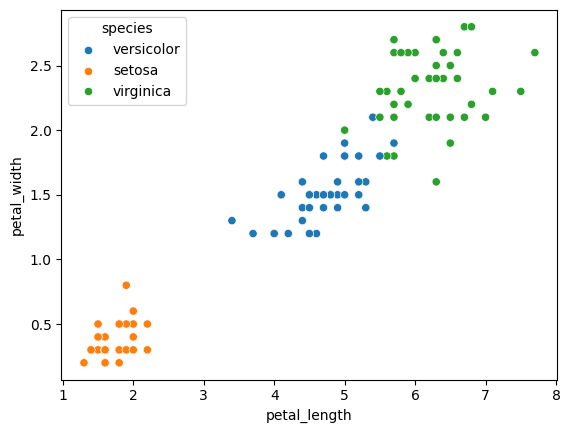

In [43]:
sns.scatterplot(data=df, x='petal_length', y='petal_width', hue=target_column);

Use a pair plot to visualize the correlations between every pair of features:

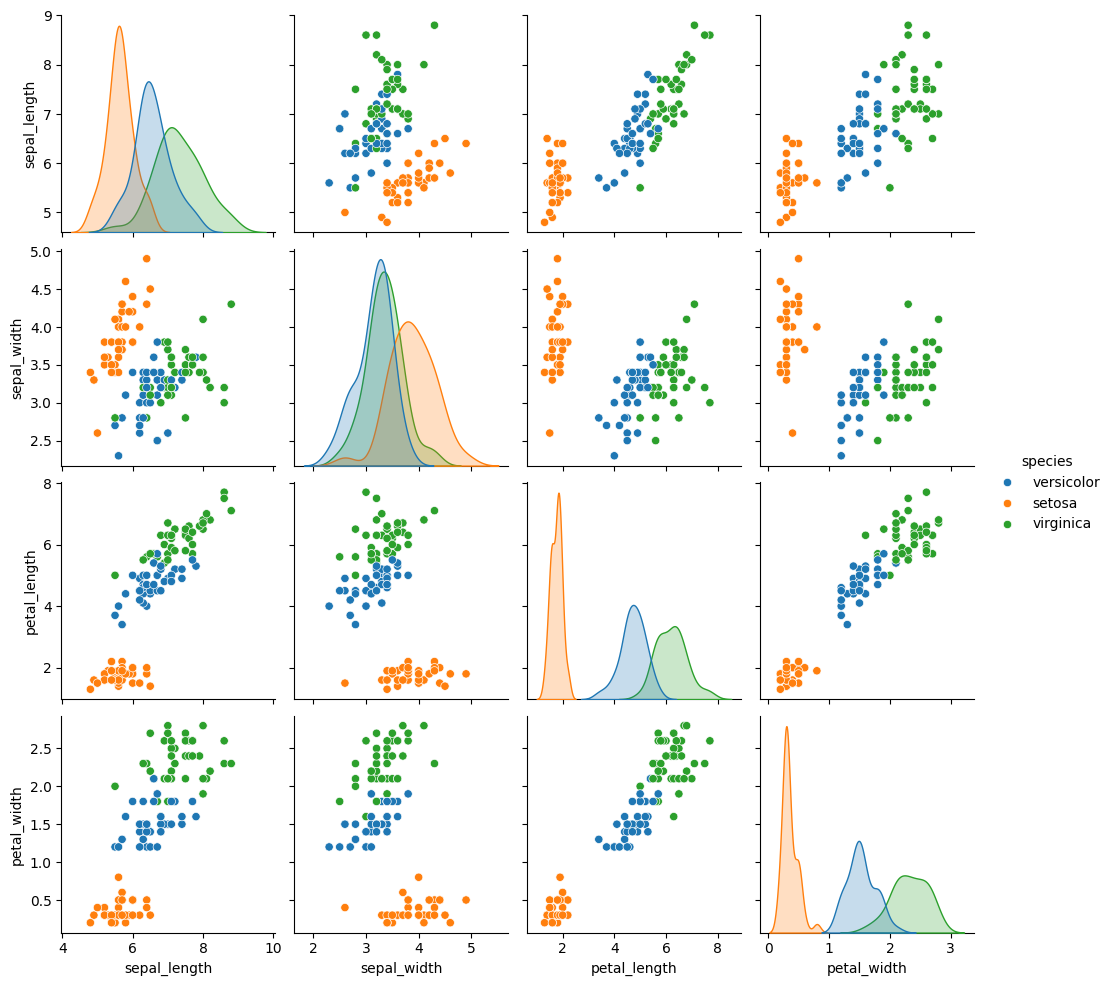

In [44]:
sns.pairplot(data=df, hue=target_column);

# Data scaling

Prepare a standard scaler to rescale (i.e. standardize) the features:

In [45]:
scaler = StandardScaler()

scaler

,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


Fit the scaler to the training data:

In [46]:
scaler.fit(df[feature_columns])

StandardScaler()

The scaler has learned the mean and standard deviation of each feature:

In [47]:
pd.DataFrame({'mean': scaler.mean_, 'scale': scaler.scale_}, index=feature_columns)

,mean,scale
sepal_length,6.505000,0.867165
sepal_width,3.459167,0.478974
petal_length,4.227500,1.907353
petal_width,1.401667,0.839145


Use the scaler to transform each feature to zero mean and unit variance:

In [48]:
df[feature_columns] = scaler.transform(df[feature_columns])

df

,sepal_length,sepal_width,petal_length,petal_width,species
id,,,,,
1,-0.121084,-0.541087,0.195297,0.117183,versicolor
2,-1.043631,0.294031,-1.482421,-1.312845,setosa
3,0.570826,-1.793765,0.352583,0.117183,versicolor
4,-0.582358,1.964269,-1.167849,-1.074507,setosa
5,-0.582358,1.546709,-1.272707,-1.312845,setosa
...,...,...,...,...,...
116,-1.274267,-0.123528,-1.377564,-1.432014,setosa
117,-0.005766,-0.749867,0.772012,0.951365,virginica
118,1.378054,0.294031,1.139013,1.428041,virginica


Plot the data to verify that each feature is now centered around zero:

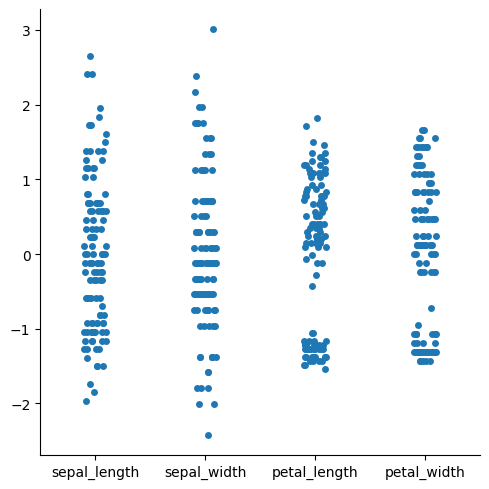

In [49]:
sns.catplot(data=df, color='tab:blue');

Plot the same data points with a visual indication of the class they belong to:

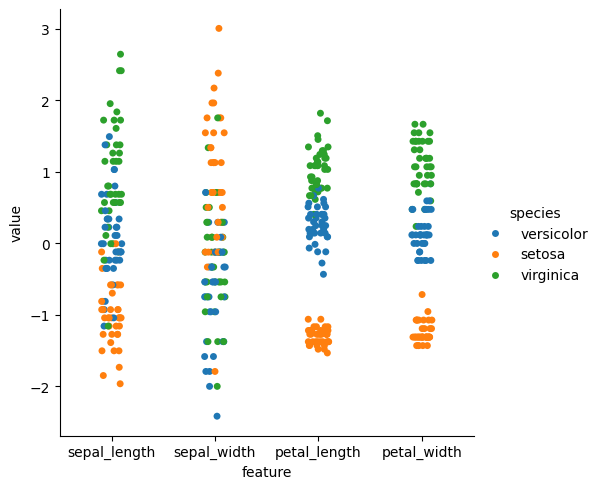

In [50]:
melt = df.melt(id_vars=target_column,
               value_vars=feature_columns,
               var_name='feature',
               value_name='value')

sns.catplot(data=melt,
            x='feature',
            y='value',
            hue=target_column);

# Data splitting

Split the training data into a training set and a validation set:

In [51]:
df_train, df_valid = train_test_split(df,
                                      test_size=0.2,
                                      random_state=0,
                                      stratify=df[target_column])

print(df_train.shape, df_valid.shape)

(96, 5) (24, 5)


The use of *stratify* above ensures that the training set and the validation set have the same class distribution.

In terms of absolute counts, we have:

In [52]:
pd.concat({'train': df_train[target_column].value_counts(),
           'valid': df_valid[target_column].value_counts()}, axis=1)

,train,valid
species,,
setosa,32,8
versicolor,32,8
virginica,32,8


In terms of relative percentages, we have:

In [53]:
pd.concat({'train': df_train[target_column].value_counts(normalize=True),
           'valid': df_valid[target_column].value_counts(normalize=True)}, axis=1).style.format('{:.1%}')

,train,valid
species,,
setosa,33.3%,33.3%
versicolor,33.3%,33.3%
virginica,33.3%,33.3%


# Model fitting

Create a kNN (*k*-nearest neighbors) classifier:

In [54]:
model = KNeighborsClassifier(n_neighbors=5)

model

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None


Fit the classifier to the traning set:

In [55]:
model.fit(df_train[feature_columns], df_train[target_column])

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](3,)","['setosa','versicolor','virginica']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


# Model evaluation

For evaluation purposes, use the classifier to make predictions on the validation set:

In [56]:
predict_column = 'prediction'

df_valid[predict_column] = model.predict(df_valid[feature_columns])

df_valid

,sepal_length,sepal_width,petal_length,petal_width,species,prediction
id,,,,,,
107,0.570826,-0.749867,0.667155,0.832197,virginica,virginica
70,1.839327,-0.332308,1.453585,0.832197,virginica,virginica
65,-0.005766,2.173048,-1.482421,-1.312845,setosa,setosa
97,-0.121084,-0.123528,0.247726,-0.001986,versicolor,versicolor
7,-0.582358,0.711591,-1.272707,-1.074507,setosa,setosa
17,-1.158949,0.085252,-1.272707,-1.432014,setosa,setosa
57,0.686144,-0.541087,1.086585,1.308872,virginica,virginica
100,-0.351721,-1.584986,-0.014418,-0.240324,versicolor,versicolor
2,-1.043631,0.294031,-1.482421,-1.312845,setosa,setosa


Check the accuracy of those predictions:

In [57]:
accuracy_score(df_valid[target_column], df_valid[predict_column])

0.9166666666666666

Note that we can get the same result by computing accurary as follows:

In [58]:
n1 = (df_valid[target_column] == df_valid[predict_column]).sum()
n2 = (df_valid[target_column] != df_valid[predict_column]).sum()

print(n1 / (n1 + n2))

0.9166666666666666


Plot the confusion matrix for true vs. predicted labels on the validation set:

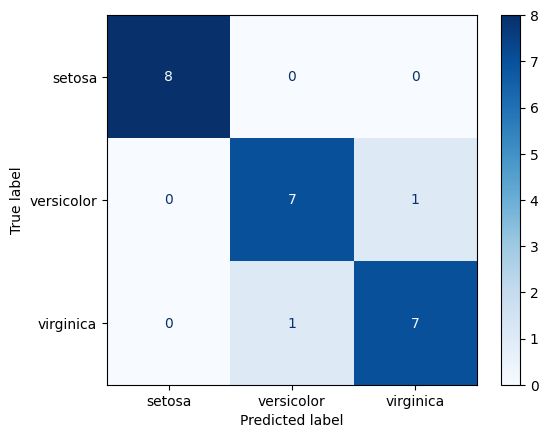

In [59]:
ConfusionMatrixDisplay.from_predictions(df_valid[target_column],
                                        df_valid[predict_column],
                                        cmap='Blues');

Take a moment to interpret this confusion matrix.

# Test data

Read the test data from a CSV file, using the *id* column as index:

In [60]:
df_test = pd.read_csv(os.path.join(path, 'test.csv'), index_col='id')

df_test

,sepal_length,sepal_width,petal_length,petal_width
id,,,,
121,6.2,2.7,4.3,1.3
122,5.4,3.4,1.6,0.4
123,7.5,3.7,6.4,2.8
124,7.2,3.6,5.7,2.3
125,4.9,3.4,1.5,0.3
126,5.3,3.6,1.5,0.3
127,8.6,3.4,6.8,2.6
128,7.0,2.8,5.5,1.8
129,6.7,3.4,5.4,2.1


Apply the same standard scaler to the test data:

In [61]:
df_test[feature_columns] = scaler.transform(df_test[feature_columns])

df_test

,sepal_length,sepal_width,petal_length,petal_width
id,,,,
121,-0.351721,-1.584986,0.038011,-0.121155
122,-1.274267,-0.123528,-1.377564,-1.193676
123,1.147417,0.502811,1.139013,1.666379
124,0.801462,0.294031,0.772012,1.070534
125,-1.850859,-0.123528,-1.429993,-1.312845
126,-1.389586,0.294031,-1.429993,-1.312845
127,2.415919,-0.123528,1.348728,1.428041
128,0.570826,-1.376206,0.667155,0.474690
129,0.224871,-0.123528,0.614726,0.832197


Make predictions on the test set:

In [62]:
df_test[target_column] = model.predict(df_test[feature_columns])

df_test

,sepal_length,sepal_width,petal_length,petal_width,species
id,,,,,
121,-0.351721,-1.584986,0.038011,-0.121155,versicolor
122,-1.274267,-0.123528,-1.377564,-1.193676,setosa
123,1.147417,0.502811,1.139013,1.666379,virginica
124,0.801462,0.294031,0.772012,1.070534,virginica
125,-1.850859,-0.123528,-1.429993,-1.312845,setosa
126,-1.389586,0.294031,-1.429993,-1.312845,setosa
127,2.415919,-0.123528,1.348728,1.428041,virginica
128,0.570826,-1.376206,0.667155,0.474690,virginica
129,0.224871,-0.123528,0.614726,0.832197,versicolor


Prepare a submission:

In [63]:
df_submission = df_test[target_column].to_frame()

df_submission

,species
id,
121,versicolor
122,setosa
123,virginica
124,virginica
125,setosa
126,setosa
127,virginica
128,virginica
129,versicolor


Save the submission file:

In [64]:
df_submission.to_csv('submission.csv')

Submit this file to the competition, and check your score on the leaderboard!🍀

**Leaderboard Score:** `0.966` (Tied **#1** class overall)